# The support floor and the watch list: when is a pair too thin?

**Week 4, Wednesday, chapter 6 of the concept block.** The topic, in the curriculum's words: *The support floor and the watch list*.
The examples are invented for this chapter, small enough to count by hand: every number below is counted from a table in `data/`, and the code only confirms the count.

**Who needs the answer.** The canteen manager, who sees gulab jamun and curd read lift 6.0, the canteen's strongest pair, and must decide whether one order is enough to print a combo card.

**The questions on the way.** How much can luck move a lift? What is a floor? What does a watch list do? Where does each pair go?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
from collections import Counter
from itertools import combinations

lines = pd.read_csv("../data/C2_W04_D03_canteen_order_lines_STUDENT.csv")
month = pd.read_csv("../data/C2_W04_D03_canteen_month_STUDENT.csv")
baskets = lines.groupby("order_id").item.apply(set)
month_baskets = month.groupby("order_id").item.apply(set)
print(f"the twelve orders, invented: {len(lines)} lines in {len(baskets)} orders")
print(f"a month of the canteen, invented so that no item depends on another: "
      f"{len(month_baskets)} orders, {month.item.nunique()} items, {len(month):,} lines")


def pairs_of(bs):
    """Every pair found in the baskets, with the orders holding both, chance, and lift."""
    n = len(bs)
    single = Counter(x for b in bs for x in b)
    count = Counter(p for b in bs for p in combinations(sorted(b), 2))
    return pd.DataFrame([{"a": a, "b": b, "both": k, "chance": single[a] * single[b] / n,
                          "lift": k * n / (single[a] * single[b])} for (a, b), k in count.items()])


canteen = pairs_of(baskets)
check("600 orders and 14 items in the month", len(month_baskets) == 600 and month.item.nunique() == 14)

the twelve orders, invented: 33 lines in 12 orders
a month of the canteen, invented so that no item depends on another: 600 orders, 14 items, 1,579 lines
PASS 600 orders and 14 items in the month


## In 600 orders of pure chance, how high can a lift go?

Week 1 Thursday's rule was to distrust any rate built on fewer than thirty observations.
Gulab jamun and curd read lift 6.0 on one of the twelve orders. The month below was
invented so that no item depends on another: every item goes into an order on its own
coin, so nothing pulls any pair together, and since an order must hold at least one item,
every true lift sits a shade under one.

**Predict before you run.** On one or two orders, how high can a lift read?

a) About 1.2, since items that ignore each other stay near one.
b) About 2, since luck can double a lift and no more.
c) About 3, since luck can triple it.
d) Above 6, more than six times chance.

In [2]:
m = pairs_of(month_baskets)
thin, thick = m[m.both <= 2], m[m.both >= 30]
top = thin.sort_values("lift").iloc[-1]
one = m[m.both == 1].sort_values("lift").iloc[-1]
print(f"{len(m)} pairs; {len(thin)} sit on one or two orders")
print(f"strongest of those: {top.a} + {top.b}, lift {top.lift:.2f} on {top.both} orders, "
      f"where chance gives {top.chance:.2f}")
print(f"strongest pair on a single order: lift {one.lift:.2f}")
print(f"{len(thick)} pairs on 30 or more orders read lift {thick.lift.min():.2f} to {thick.lift.max():.2f}")
check("a thin pair reads lift above 6 in a month of pure chance", top.lift > 6)
check("every pair on thirty or more orders sits near one", thick.lift.between(0.85, 1.05).all())

63 pairs; 19 sit on one or two orders
strongest of those: gulab jamun + jalebi, lift 8.57 on 2 orders, where chance gives 0.23
strongest pair on a single order: lift 5.88
10 pairs on 30 or more orders read lift 0.90 to 1.00
PASS a thin pair reads lift above 6 in a month of pure chance
PASS every pair on thirty or more orders sits near one


**What happened.** The answer is d. Nothing in this month pulls any item toward another,
yet gulab jamun and jalebi read lift 8.57 on
2 orders, where chance gives
0.23. The 10 pairs on 30 or more
orders read 0.90 to 1.00, a shade under one.
In between, three pairs on 4 to 7 orders still pass 1.5, up to
1.83, and none on 8 or more orders
does. A lift on a handful of baskets says more about luck than about the pair. The picture
reads left to right: wild on the left, flat on the right.

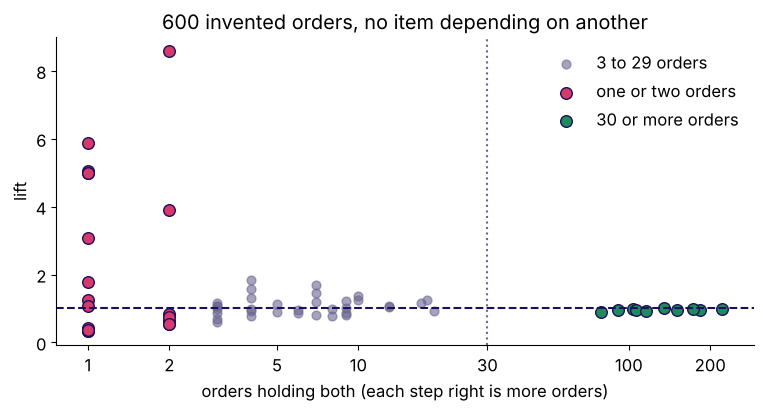

In [3]:
mid = m[(m.both > 2) & (m.both < 30)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(mid.both, mid.lift, s=40, color="#6B6690", alpha=0.6, label="3 to 29 orders")
ax.scatter(thin.both, thin.lift, s=70, color="#D63A6A", edgecolor="#1A0F5C", label="one or two orders")
ax.scatter(thick.both, thick.lift, s=70, color="#1F8A5B", edgecolor="#1A0F5C", label="30 or more orders")
ax.axhline(1, color="#1A0F5C", ls="--")
ax.axvline(30, color="#6B6690", ls=":")
ax.set_xscale("log")
ax.set_xticks([1, 2, 5, 10, 30, 100, 200], ["1", "2", "5", "10", "30", "100", "200"])
ax.minorticks_off()
ax.set_xlabel("orders holding both (each step right is more orders)")
ax.set_ylabel("lift")
ax.legend(frameon=False)
ax.set_title("600 invented orders, no item depending on another")
plt.show()

## Where does each canteen pair go once a floor is set?

A **support floor** is the fewest baskets a pair must sit in before anyone acts on its
lift. It is a decision, stated as a count before the ranking is read, and it belongs where
luck stops carrying a lift past the bar: 8 orders in the
month above, Week 1's thirty when no such month is to hand, 1 percent of the carts in the
case. Twelve orders are too few for any floor, so a floor of 3 here only shows the sort.
The rule, named last: read a lift only at or above the floor, and promote only at a lift
of 1.5 or more. That sorts every pair into four regions: promote, watch (strong but thin),
trap (near one on plenty of baskets) and ignore. Roti and sabzi, 2.25 on three orders,
lands in promote and would still be trialled first.

       a           b  both  chance  lift  region
    curd gulab jamun     1    0.17  6.00   watch
   papad      pickle     2    0.83  2.40   watch
    roti       sabzi     3    1.33  2.25 promote
  pickle        roti     1    0.67  1.50   watch
   chaas    dal rice     6    4.50  1.33    trap
   chaas       sabzi     4    3.00  1.33    trap
dal rice       papad     3    2.50  1.20    trap
    curd    dal rice     1    1.00  1.00  ignore
   chaas        roti     3    3.00  1.00    trap
   chaas       papad     3    3.75  0.80    trap
   chaas        curd     1    1.50  0.67  ignore
   papad        roti     1    1.67  0.60  ignore
dal rice       sabzi     1    2.00  0.50  ignore


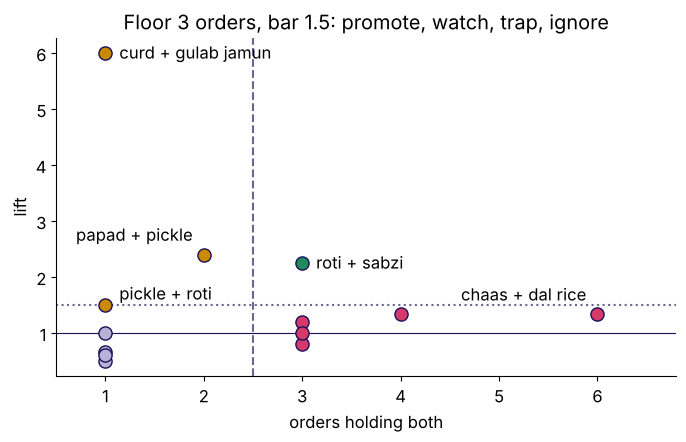

PASS only roti and sabzi are promoted
PASS papad and pickle, and gulab jamun and curd, go on the watch list


In [4]:
FLOOR, BAR = 3, 1.5     # orders, lift


def region(k, lift):
    strong = lift >= BAR
    if k >= FLOOR:
        return "promote" if strong else "trap"
    return "watch" if strong else "ignore"


canteen["region"] = [region(k, l) for k, l in zip(canteen.both, canteen.lift)]
print(canteen.sort_values("lift", ascending=False).round(2).to_string(index=False))
colour = {"promote": "#1F8A5B", "watch": "#C98A00", "trap": "#D63A6A", "ignore": "#B8B2D6"}
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.axvline(FLOOR - 0.5, color="#6B6690", ls="--")
ax.axhline(BAR, color="#6B6690", ls=":")
ax.axhline(1, color="#1A0F5C", lw=0.8)
for r in canteen.itertuples():
    ax.scatter(r.both, r.lift, s=90, color=colour[r.region], edgecolor="#1A0F5C", zorder=3)
place = {("curd", "gulab jamun"): (10, -4, "left"), ("papad", "pickle"): (-8, 10, "right"),
         ("roti", "sabzi"): (10, -4, "left"), ("pickle", "roti"): (10, 4, "left"),
         ("chaas", "dal rice"): (-8, 10, "right")}
for r in canteen.itertuples():
    if (r.a, r.b) in place:
        dx, dy, ha = place[(r.a, r.b)]
        ax.annotate(f"{r.a} + {r.b}", (r.both, r.lift), xytext=(dx, dy), textcoords="offset points", ha=ha)
ax.set_xlim(0.5, 6.8)
ax.set_xlabel("orders holding both")
ax.set_ylabel("lift")
ax.set_title("Floor 3 orders, bar 1.5: promote, watch, trap, ignore")
plt.show()
promote = canteen[canteen.region == "promote"]
check("only roti and sabzi are promoted", list(zip(promote.a, promote.b)) == [("roti", "sabzi")])
check("papad and pickle, and gulab jamun and curd, go on the watch list",
      {("papad", "pickle"), ("curd", "gulab jamun")} <= set(zip(canteen[canteen.region == "watch"].a,
                                                                 canteen[canteen.region == "watch"].b)))

## What does a watch list do with a strong pair below the floor?

A pair above the bar and below the floor goes on a **watch list**: the pair, its lift and
its count, a trial (where, for how long, and against which other half of customers) and a
pass rule written before the trial starts. A **pass rule** says what the trial must show:
the half that sees the pair buys it more often than the other half, by a gap fixed in
advance. Gulab jamun and curd, lift
6.00 on one order, earn a trial and never a printed card. How
long a trial must run is a sample-size question for the IITGN faculty session (tentative).
The picture shows why the floor is a decision: lower it and the one-order pairs flood in.

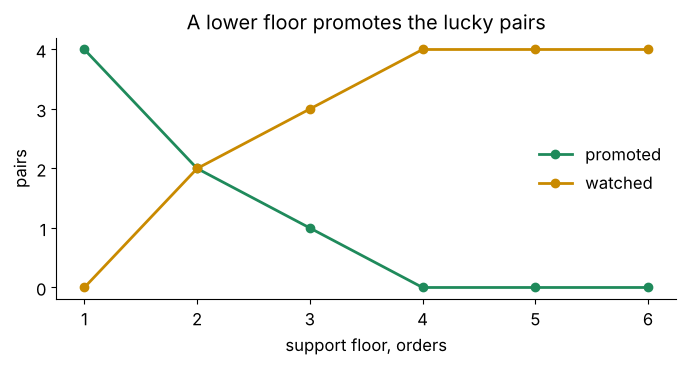

PASS a floor of one order would promote gulab jamun and curd; a floor of three does not


In [5]:
floors = range(1, 7)
promoted = [sum(1 for k, l in zip(canteen.both, canteen.lift) if k >= f and l >= BAR) for f in floors]
watched = [sum(1 for k, l in zip(canteen.both, canteen.lift) if k < f and l >= BAR) for f in floors]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(list(floors), promoted, marker="o", color="#1F8A5B", lw=2, label="promoted")
ax.plot(list(floors), watched, marker="o", color="#C98A00", lw=2, label="watched")
ax.set_xlabel("support floor, orders")
ax.set_ylabel("pairs")
ax.legend(frameon=False)
ax.set_title("A lower floor promotes the lucky pairs")
plt.show()
check("a floor of one order would promote gulab jamun and curd; a floor of three does not",
      region(1, 6.0) == "watch" and promoted[0] > promoted[2])

### Your turn: which of the month's pairs clear a floor of 15 orders?

In the empty cell below, keep the month's pairs (`m`) on at least 15 orders, and store
how many there are as `floor15_count` and their lowest and highest lift, as a pair of
numbers, as `floor15_range`. Then run the check under it, and say in a comment whether any
of them would pass the 1.5 bar.

In [6]:
mine = (globals().get("floor15_count"), globals().get("floor15_range"))
if None in mine:
    print("Store your answers as floor15_count and floor15_range in the empty cell above, then run this cell again.")
else:
    ref = m[m.both >= 15]
    print(f"reference: {len(ref)} pairs, lift {ref.lift.min():.2f} to {ref.lift.max():.2f}")
    ok = (mine[0] == len(ref) and abs(min(mine[1]) - ref.lift.min()) <= 0.005
          and abs(max(mine[1]) - ref.lift.max()) <= 0.005)
    print("matches at two decimals" if ok else "not yet: filter on both >= 15 first")

Store your answers as floor15_count and floor15_range in the empty cell above, then run this cell again.


## What should you keep from chapter 6?

- A lift on one or two baskets swings by luck: 8.57 on
  2 orders in a month where every true lift is one.
- The floor is a count of baskets set where luck stops carrying a lift past the bar,
  before the ranking is read: 8 orders in the month,
  3 on the twelve only to show the sort.
- A strong pair below the floor goes on a watch list: a trial on a random half of
  customers, its pass rule written first, shows whether the pull is real and whether it
  sells.
- A pair near one is never promoted: below the floor it is ignored, and above it, where a
  count ranks it first, it is the trap.

**In the interview.** "A pair has a high lift on very few baskets; act or not?" Watch it:
test it on a random half of customers with a pass rule set first. Chapter 7 refuses a
lift of 12 on one Instamart cart, and chapter 10 sets the case's floor at 1 percent of
carts.